/var/folders/sn/3w7f5r7d14j3x2_h9q6xz_140000gn/T/ipykernel_29883/1037147214.py:12: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Dataset Shape:
(10000, 31)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


%|                                                    | 0/31 [00:00<?, ?it/s]
%|███████                                     | 5/31 [00:00<00:00, 29.47it/s]
%|█████████████▊                             | 10/31 [00:00<00:00, 32.00it/s]
%|███████████████████▍                       | 14/31 [00:00<00:00, 33.09it/s]
%|████████████████████████▉                  | 18/31 [00:00<00:00, 29.85it/s]
%|██████████████████████████████▌            | 22/31 [00:00<00:00, 27.73it/s]
100%|███████████████████████████████████████████| 31/31 [00:00<00:00, 35.34it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

HTML Report generated successfully!

Numerical Variables:
Index(['age', 'tenure_months', 'monthly_logins', 'weekly_active_days',
       'avg_session_time', 'features_used', 'usage_growth_rate',
       'last_login_days_ago', 'monthly_fee', 'total_revenue',
       'payment_failures', 'support_tickets', 'avg_resolution_time',
       'csat_score', 'escalations', 'email_open_rate', 'marketing_click_rate',
       'nps_score', 'referral_count'],
      dtype='object')


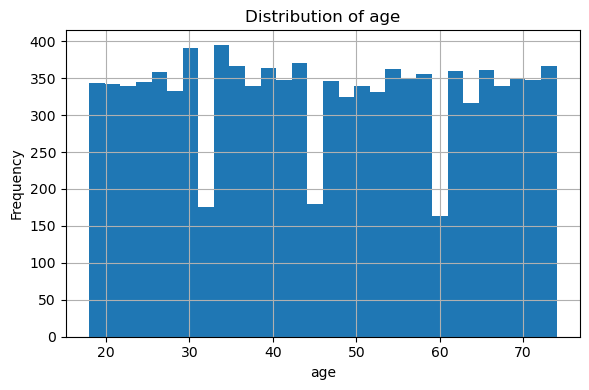

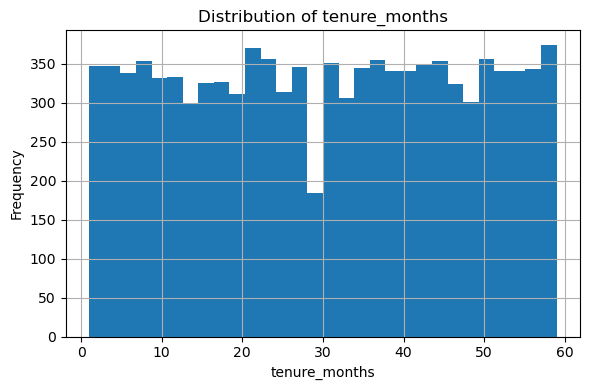

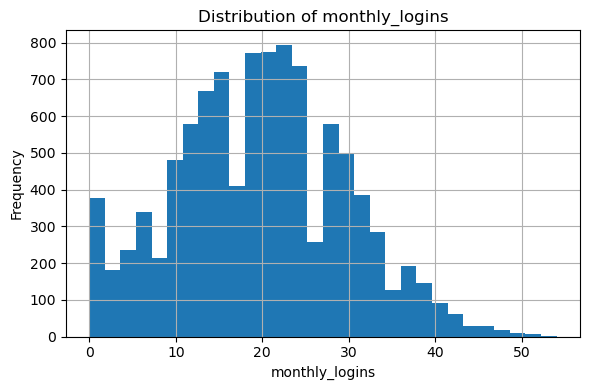

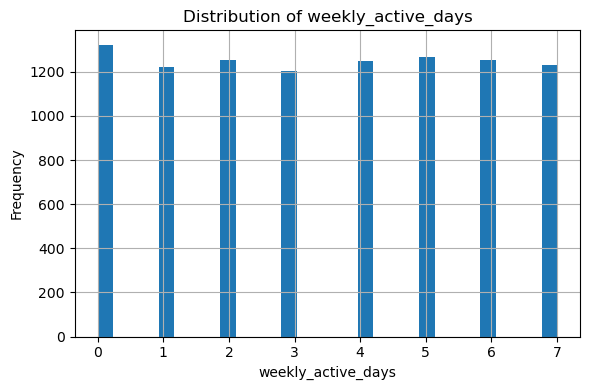

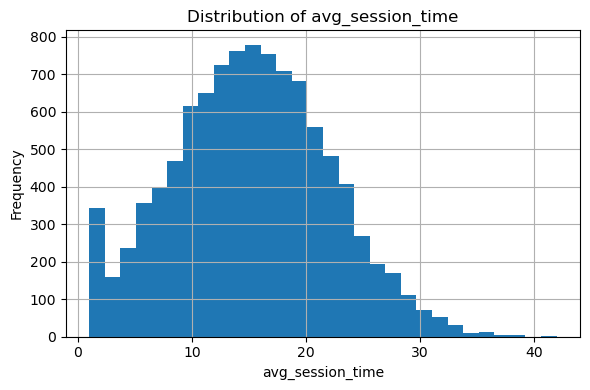

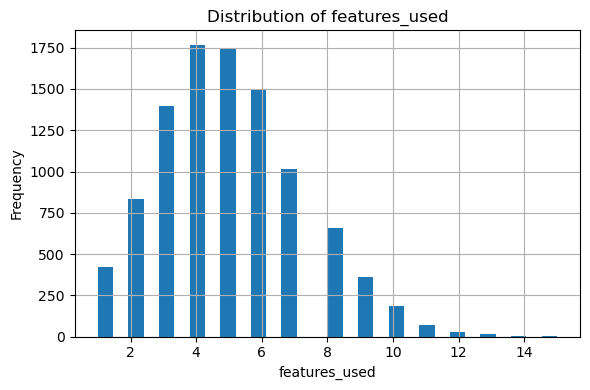

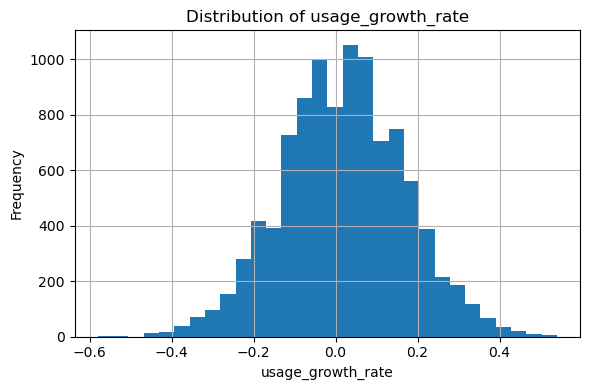

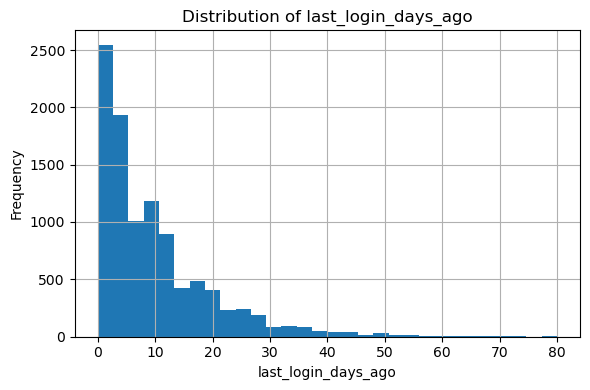

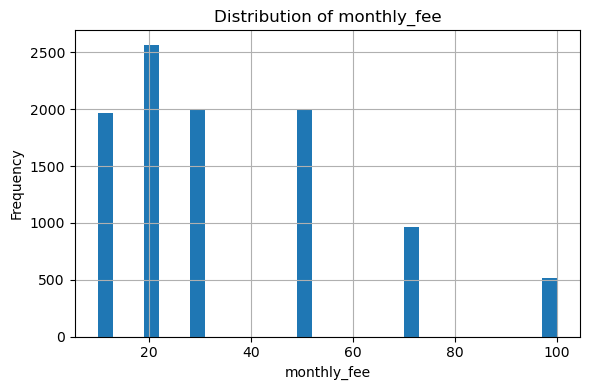

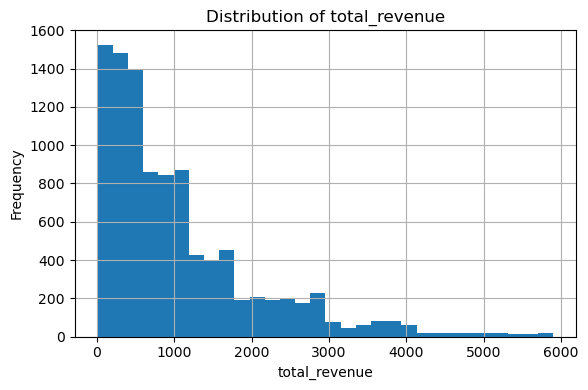

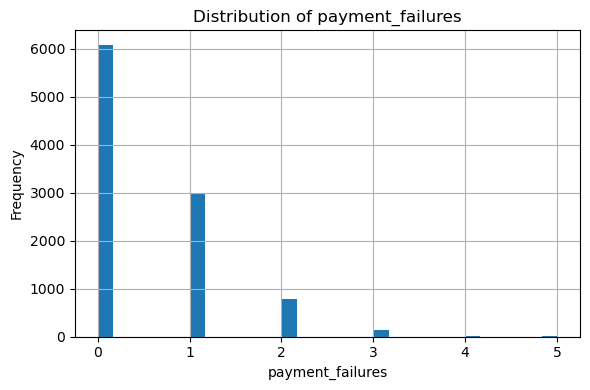

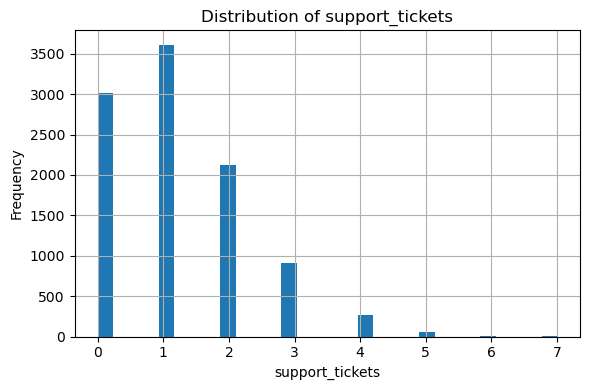

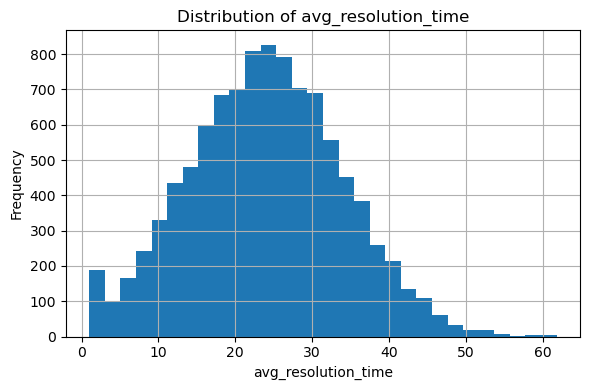

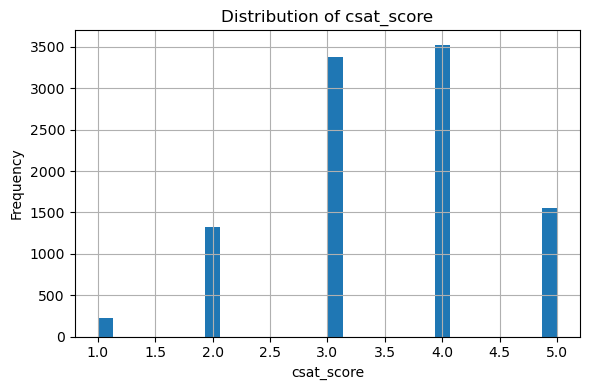

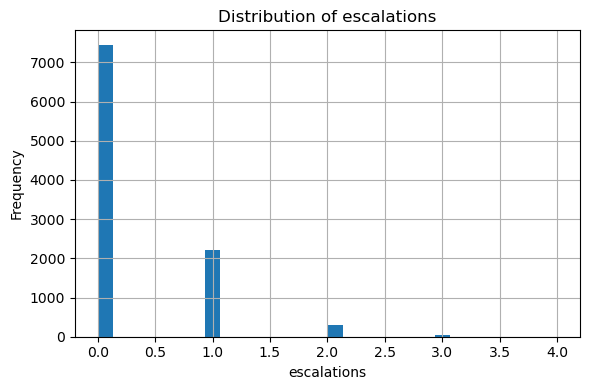

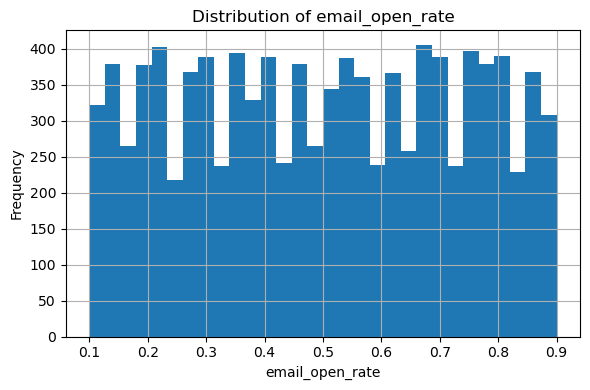

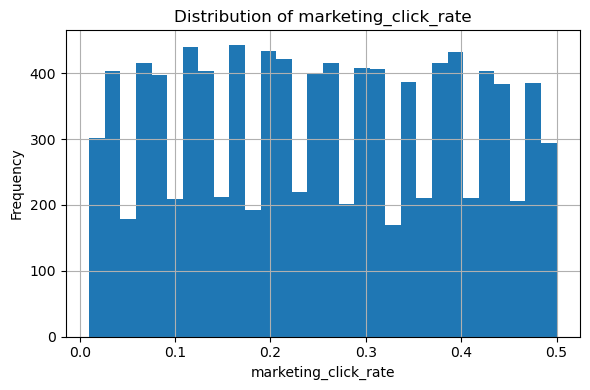

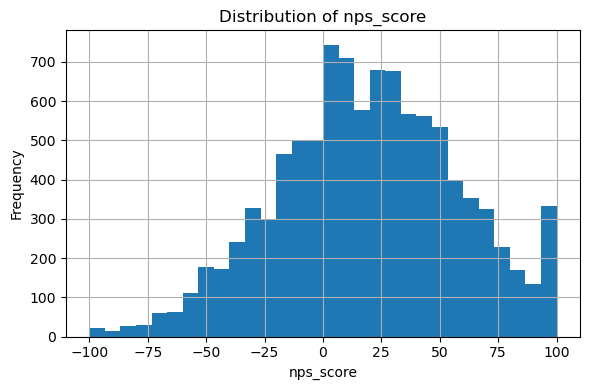

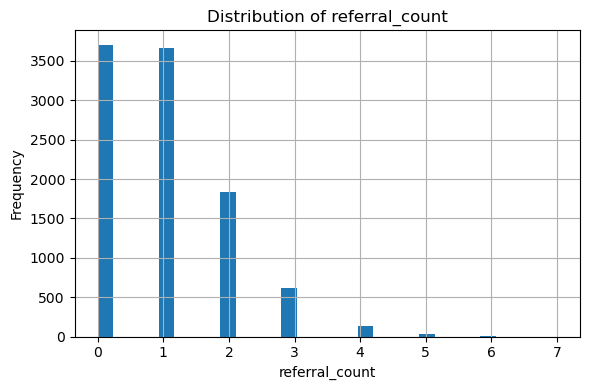


Categorical Variables:
Index(['gender', 'country', 'city', 'customer_segment', 'signup_channel',
       'contract_type', 'payment_method', 'discount_applied',
       'price_increase_last_3m', 'complaint_type', 'survey_response'],
      dtype='object')


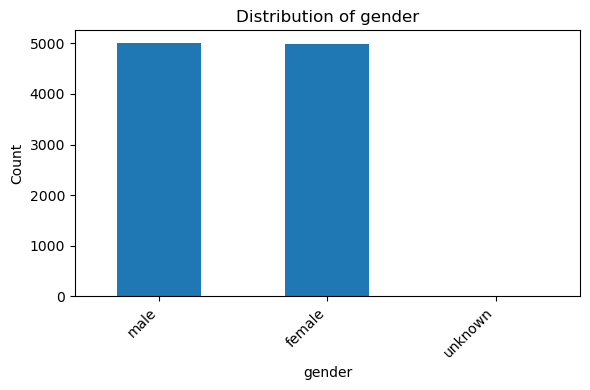

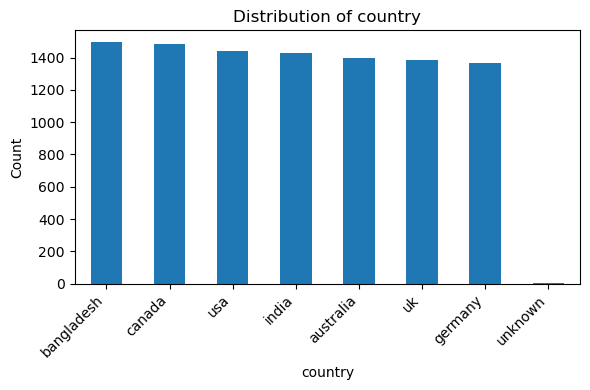

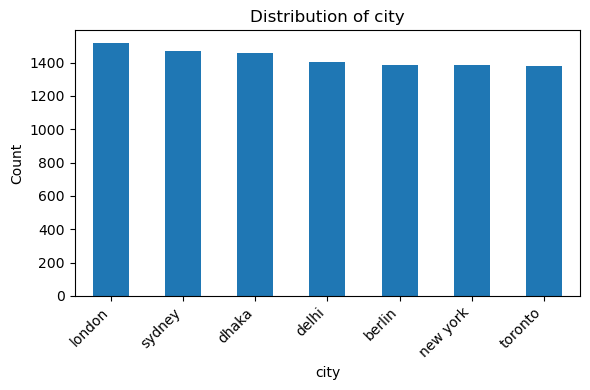

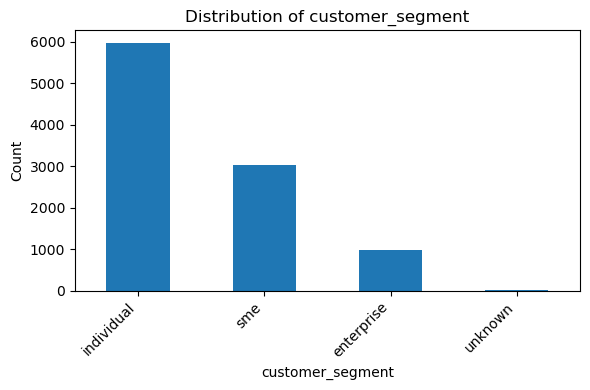

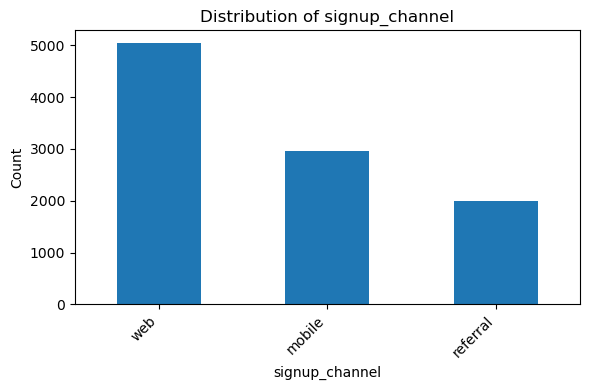

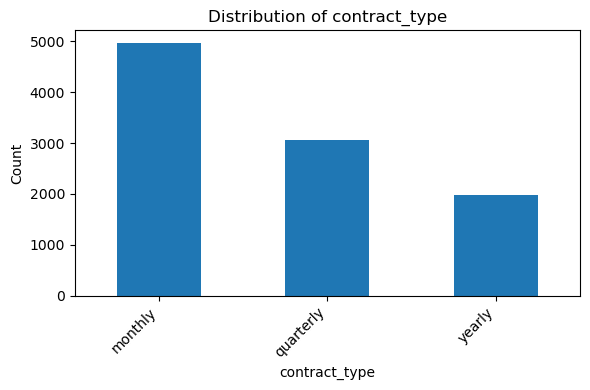

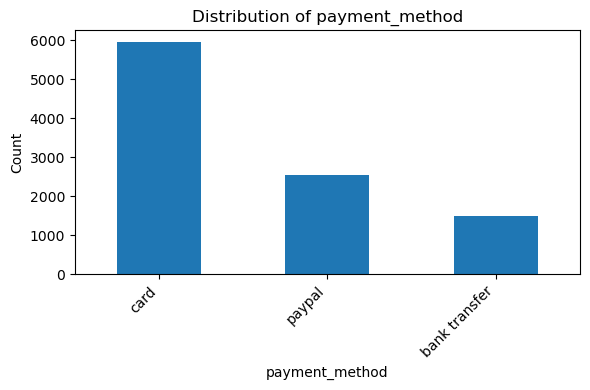

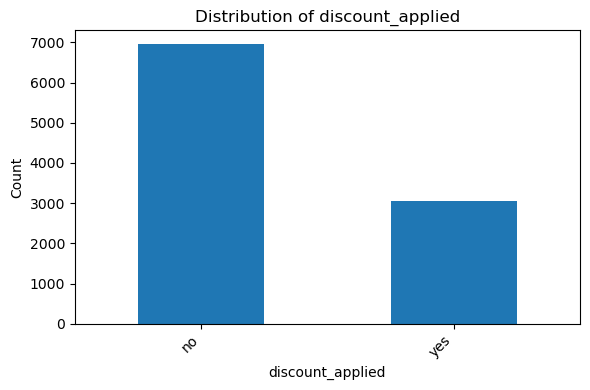

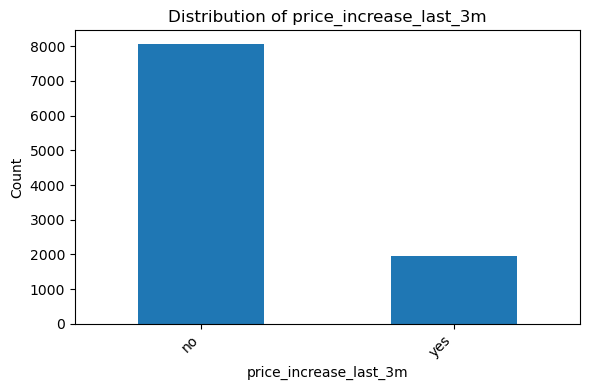

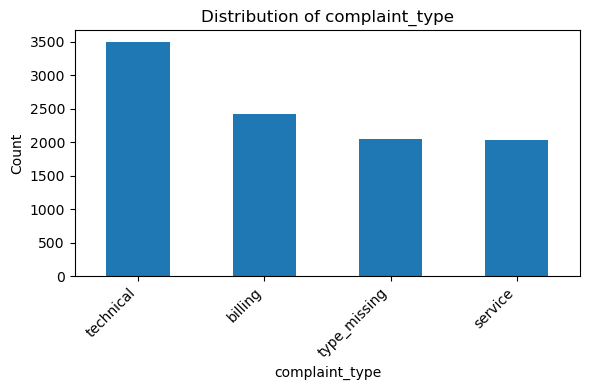

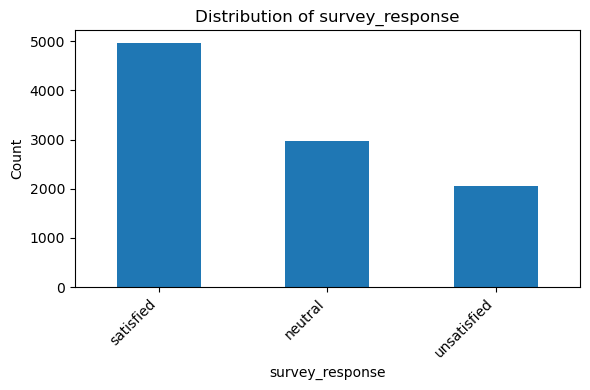

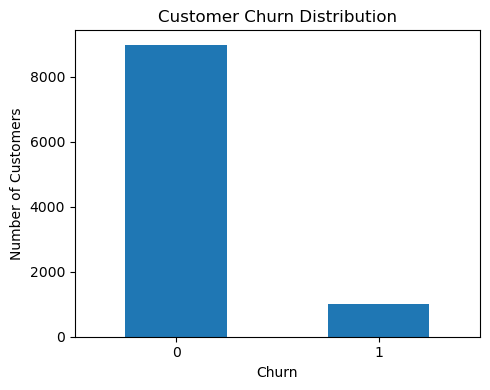

DATASET PROFILING SUMMARY
Number of Rows: 10000
Number of Columns: 31
Missing Values: 0
Duplicate Rows: 0

Data Types:
int64      13
object     11
float64     7
Name: count, dtype: int64

Churn Distribution:
churn
0    8979
1    1021
Name: count, dtype: int64

Churn Percentage:
churn
0    89.79
1    10.21
Name: proportion, dtype: float64
DATASET PROFILING COMPLETED SUCCESSFULLY


In [1]:
# ==========================================
# Customer Churn Dataset Profiling
# ==========================================


# Enable inline plotting for Jupyter Notebook
%matplotlib inline


# Import libraries

from ydata_profiling import ProfileReport
import pandas as pd
import matplotlib.pyplot as plt



# ==========================================
# Load Cleaned Dataset
# ==========================================


CustomerData_Df = pd.read_csv(
    "/Users/manesh/Library/CloudStorage/OneDrive-UniversityofPlymouth/Dissertation /Python_Code/customer_churn_cleaned.csv"
)


# Check dataset

print("Dataset Shape:")
print(CustomerData_Df.shape)


CustomerData_Df.head()



# ==========================================
# Generate YData Profiling Report
# ==========================================


profile = ProfileReport(
    CustomerData_Df,
    title="Customer Churn Dataset Profiling Report",
    explorative=True
)


profile.to_file(
    "customer_churn_profiling_report.html"
)


print("HTML Report generated successfully!")



# ==========================================
# Identify Numerical Variables
# ==========================================


numerical_cols = (
    CustomerData_Df
    .select_dtypes(include=['int64','float64'])
    .columns
    .drop('churn')
)



print("\nNumerical Variables:")

print(numerical_cols)



# ==========================================
# Numerical Variable Distributions
# ==========================================


for col in numerical_cols:

    plt.figure(figsize=(6,4))

    CustomerData_Df[col].hist(
        bins=30
    )

    plt.title(
        f'Distribution of {col}'
    )

    plt.xlabel(col)

    plt.ylabel(
        "Frequency"
    )

    plt.tight_layout()

    plt.show()

    plt.close()



# ==========================================
# Identify Categorical Variables
# ==========================================


cat_cols = CustomerData_Df.select_dtypes(
    include=['object']
).columns



print("\nCategorical Variables:")

print(cat_cols)



# ==========================================
# Categorical Variable Distributions
# ==========================================


for col in cat_cols:

    plt.figure(figsize=(6,4))


    CustomerData_Df[col].value_counts().plot(
        kind='bar'
    )


    plt.title(
        f'Distribution of {col}'
    )


    plt.xlabel(
        col
    )


    plt.ylabel(
        "Count"
    )


    plt.xticks(
        rotation=45,
        ha='right'
    )


    plt.tight_layout()


    plt.show()

    plt.close()



# ==========================================
# Target Variable Distribution
# ==========================================


plt.figure(figsize=(5,4))


CustomerData_Df['churn'].value_counts().plot(
    kind='bar'
)


plt.title(
    "Customer Churn Distribution"
)


plt.xlabel(
    "Churn"
)


plt.ylabel(
    "Number of Customers"
)


plt.xticks(
    rotation=0
)


plt.tight_layout()


plt.show()

plt.close()



# ==========================================
# Final Profiling Summary
# ==========================================


print("="*60)

print("DATASET PROFILING SUMMARY")

print("="*60)


print(
"Number of Rows:",
CustomerData_Df.shape[0]
)


print(
"Number of Columns:",
CustomerData_Df.shape[1]
)


print(
"Missing Values:",
CustomerData_Df.isnull().sum().sum()
)


print(
"Duplicate Rows:",
CustomerData_Df.duplicated().sum()
)


print("\nData Types:")

print(
CustomerData_Df.dtypes.value_counts()
)


print("\nChurn Distribution:")

print(
CustomerData_Df['churn'].value_counts()
)


print("\nChurn Percentage:")

print(
CustomerData_Df['churn']
.value_counts(normalize=True)
*100
)


print("="*60)

print(
"DATASET PROFILING COMPLETED SUCCESSFULLY"
)

print("="*60)